# Notebook 03: The ANN Paradigm & Inverted File Index (IVF)

Welcome to the third notebook in the **Vector Search & Indexing from Scratch** series!

In [Notebook 02](02_exact_brute_force_search.ipynb), we observed the fundamental constraint of exact search:
- Evaluating every single vector in a database of size $N$ takes $O(N \cdot d)$ operations.
- On large corpora ($N \ge 1,000,000$), streaming gigabytes of raw vectors from RAM into CPU caches hits the **Memory Bandwidth Wall**, capping latency at tens or hundreds of milliseconds.

To achieve sub-millisecond retrieval on large-scale RAG systems, we must break the linear $O(N)$ scan. We must enter the world of **Approximate Nearest Neighbor (ANN)** search.

---

### The Fundamental Tradeoff Triangle of ANN

Every ANN algorithm replaces exhaustive scanning with an **intelligent approximation**:

```
                       Recall (Accuracy)
                              ▲
                             / \
                            /   \
                           /     \
                          /  ANN  \
                         / Tradeoff\
                        /  Triangle \
                       /             \
      Query Speed (QPS) ◄─────────────► Memory & Build Cost
```

Instead of guaranteeing 100% exact neighbors, an ANN index guarantees:
> **"We will search only a tiny fraction (e.g., 1% to 5%) of the database, achieving a 20x to 100x speedup, while still returning 90% to 98% of the true nearest neighbors."**

---

### Inverted File Index (IVF): The Clustering Approach

The **Inverted File Index (IVF)** is one of the most widely used ANN architectures in production (powering systems like Faiss, Milvus, and pgvector).

The core concept is elegant:
1. **Space Partitioning**: Partition high-dimensional vector space into distinct geometric regions called **Voronoi Cells** using **K-Means clustering**.
2. **Posting Lists (Inverted Lists)**: Group all document vectors into inverted lists belonging to their nearest centroid.
3. **Query Routing**: When a query arrives, first compare it against the cluster centroids (a tiny set of vectors). Then, **only scan the vectors inside the closest `nprobe` clusters**!

```
 Corpus Vectors (N) ──▶ [K-Means] ──▶ Voronoi Centroids (nlist)
                                             │
      ┌──────────────────────────────────────┴──────────────────────────────────────┐
      ▼                                      ▼                                      ▼
 Centroid C_0                           Centroid C_1                           Centroid C_2
 ┌──────────────┐                       ┌──────────────┐                       ┌──────────────┐
 │ Doc 4, 12... │                       │ Doc 1, 8...  │                       │ Doc 0, 9...  │
 └──────────────┘                       └──────────────┘                       └──────────────┘
  Inverted List 0                        Inverted List 1                        Inverted List 2
```

---

### Learning Objectives in this Notebook:
1. **The ANN Paradigm**: Understand how ANN formalizes the trade-off between Recall@K, latency, and index size.
2. **Voronoi Space Partitioning**: Understand the geometry of Voronoi cells in Euclidean space and visualize them in 2D.
3. **K-Means Clustering from Scratch**: Implement the Lloyd clustering algorithm to train coarse cluster centroids.
4. **Building `IVFFlatIndex` from Scratch**:
   - Inverted list data structures.
   - The two-phase lifecycle: `train()` (coarse quantization) vs `add()` (ingestion).
   - The query phase: `search()` with `nprobe` candidate routing.
5. **The Voronoi Boundary Problem**: Mathematically and visually understand why recall drops near cluster boundaries and how `nprobe` solves it.
6. **Empirical Benchmarking & The Pareto Frontier**: Plot the Recall vs Latency tradeoff curve on our standardized Ground Truth testbed.
7. **Industry Reference**: Compare our scratch index against `faiss.IndexIVFFlat`.
8. **Pros, Cons & Failure Modes**: Understand cluster skew, centroid drift, and production maintenance rules.


---
## 1. Setup & Environment

Let's import our required libraries. We will use NumPy for all mathematical computations and Voronoi implementations, and Matplotlib for geometric and performance visualizations.


In [1]:
import time
from typing import List, Tuple, Dict, Any, Optional

import numpy as np
import matplotlib.pyplot as plt

# Set random seed for consistent clustering & benchmarks
np.random.seed(42)

print(f"NumPy version: {np.__version__}")
print("Environment configured for IVF Indexing!")


NumPy version: 2.1.3
Environment configured for IVF Indexing!


---
## 2. Space Partitioning & Voronoi Geometry

How do we divide high-dimensional space so that similar vectors end up in the same group?

### What is a Voronoi Cell?
Given a set of $C$ cluster centroids $\{\mathbf{c}_1, \mathbf{c}_2, \dots, \mathbf{c}_K\} \subset \mathbb{R}^d$, the **Voronoi Cell** associated with centroid $\mathbf{c}_j$, denoted $V(\mathbf{c}_j)$, is the set of all points in space that are closer to $\mathbf{c}_j$ than to any other centroid:

$$V(\mathbf{c}_j) = \left\{ \mathbf{x} \in \mathbb{R}^d \;\Big|\; \|\mathbf{x} - \mathbf{c}_j\|_2 \le \|\mathbf{x} - \mathbf{c}_i\|_2, \quad \forall i \ne j \right\}$$

The boundaries between neighboring Voronoi cells are hyperplanes that perpendicularly bisect the line segments connecting adjacent centroids.

Let's write a small script to generate random 2D points, cluster them into centroids, and plot their Voronoi partitioning!


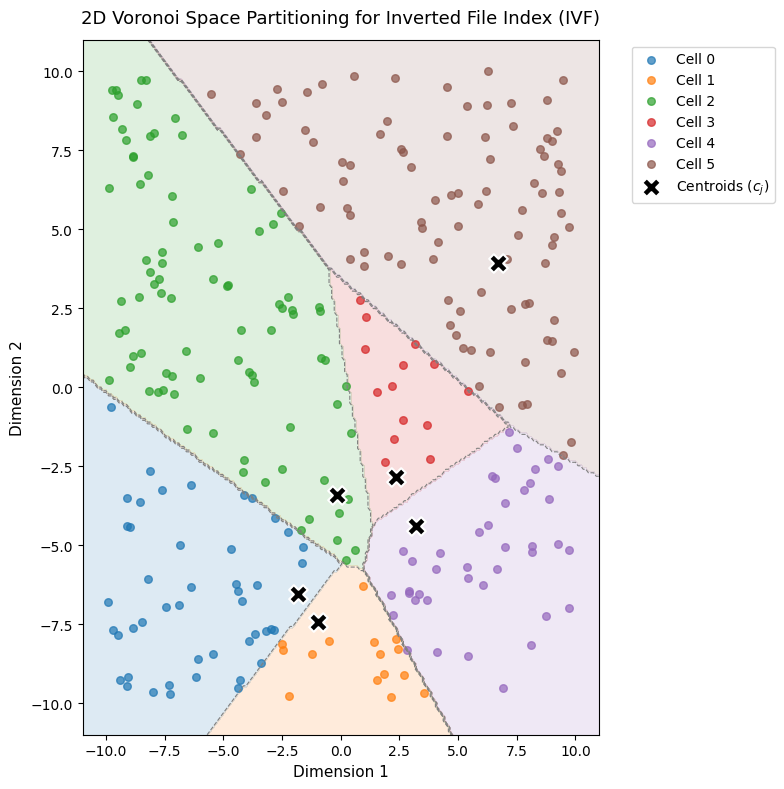

In [2]:
# Generate 2D synthetic points to visualize Voronoi cells
num_visual_points = 300
points_2d = np.random.uniform(-10, 10, size=(num_visual_points, 2))

# Select 6 random points as initial centroids
num_visual_centroids = 6
initial_indices = np.random.choice(num_visual_points, size=num_visual_centroids, replace=False)
centroids_2d = points_2d[initial_indices].copy()

# Assign every point to its closest centroid
# Shape: (num_points, 1) and (1, num_centroids) -> (num_points, num_centroids)
diffs = points_2d[:, np.newaxis, :] - centroids_2d[np.newaxis, :, :]
dists_sq = np.sum(diffs ** 2, axis=2)
assignments_2d = np.argmin(dists_sq, axis=1)

# Visualize Voronoi Regions
plt.figure(figsize=(8, 8))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

# Create background grid to color Voronoi cells
grid_x, grid_y = np.meshgrid(np.linspace(-11, 11, 200), np.linspace(-11, 11, 200))
grid_points = np.c_[grid_x.ravel(), grid_y.ravel()]
grid_diffs = grid_points[:, np.newaxis, :] - centroids_2d[np.newaxis, :, :]
grid_dists = np.sum(grid_diffs ** 2, axis=2)
grid_assignments = np.argmin(grid_dists, axis=1).reshape(grid_x.shape)

plt.contourf(grid_x, grid_y, grid_assignments, levels=np.arange(-0.5, num_visual_centroids + 0.5, 1), 
             colors=colors, alpha=0.15)
plt.contour(grid_x, grid_y, grid_assignments, levels=np.arange(num_visual_centroids), 
            colors='gray', linestyles='--', linewidths=0.8)

# Scatter data points
for c_idx in range(num_visual_centroids):
    cluster_pts = points_2d[assignments_2d == c_idx]
    plt.scatter(cluster_pts[:, 0], cluster_pts[:, 1], color=colors[c_idx], alpha=0.7, s=30, label=f"Cell {c_idx}")

# Plot Centroids
plt.scatter(centroids_2d[:, 0], centroids_2d[:, 1], color='black', marker='X', s=180, 
            edgecolors='white', linewidths=1.5, label="Centroids ($c_j$)")

plt.title("2D Voronoi Space Partitioning for Inverted File Index (IVF)", fontsize=13, pad=12)
plt.xlabel("Dimension 1", fontsize=11)
plt.ylabel("Dimension 2", fontsize=11)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


---
## 3. Training Coarse Centroids with K-Means

In an IVF index, the centroids $\{\mathbf{c}_1, \dots, \mathbf{c}_{\text{nlist}}\}$ are known as the **Coarse Quantizer**.

Before any vectors can be indexed, we must **train** the coarse quantizer on a representative sample of embeddings using **K-Means clustering** (Lloyd's Algorithm):

### The Two Steps of Lloyd's K-Means:
1. **Assignment Step**: Assign each vector $\mathbf{x}_i$ to its nearest centroid:
   $$z_i = \arg\min_{j \in [1, K]} \|\mathbf{x}_i - \mathbf{c}_j\|_2^2$$
2. **Update Step**: Recompute each centroid $\mathbf{c}_j$ as the arithmetic mean of all vectors assigned to it:
   $$\mathbf{c}_j = \frac{1}{|S_j|} \sum_{i \in S_j} \mathbf{x}_i$$

We repeat these two steps until the centroids converge or a maximum number of iterations is reached.

Let's implement a vectorized, high-performance K-Means from scratch!


In [3]:
class KMeansScratch:
    """Fast vectorized K-Means clustering in NumPy."""
    
    def __init__(self, k: int, max_iter: int = 25, tol: float = 1e-4):
        """
        Args:
            k: Number of clusters (centroids)
            max_iter: Maximum iterations
            tol: Convergence tolerance (shift in centroids)
        """
        self.k = k
        self.max_iter = max_iter
        self.tol = tol
        self.centroids: Optional[np.ndarray] = None
        
    def fit(self, X: np.ndarray) -> "KMeansScratch":
        """Train K-Means centroids on data matrix X of shape (N, d)."""
        N, d = X.shape
        if self.k > N:
            raise ValueError(f"Cannot form {self.k} clusters with only {N} samples.")
            
        # Initialize centroids randomly from data points (Forgy initialization)
        init_indices = np.random.choice(N, size=self.k, replace=False)
        self.centroids = X[init_indices].copy().astype(np.float32)
        
        for iteration in range(self.max_iter):
            # 1. Assignment step: compute squared distance to all centroids
            # Using our expansion trick: ||X - C||^2 = ||X||^2 + ||C||^2 - 2 * (X @ C.T)
            x_sq = np.sum(X ** 2, axis=1, keepdims=True)            # (N, 1)
            c_sq = np.sum(self.centroids ** 2, axis=1, keepdims=True).T # (1, k)
            dists = x_sq + c_sq - 2.0 * np.matmul(X, self.centroids.T)
            labels = np.argmin(dists, axis=1)                         # (N,)
            
            # 2. Update step: recalculate centroids
            new_centroids = np.zeros_like(self.centroids)
            counts = np.bincount(labels, minlength=self.k)
            
            for cluster_idx in range(self.k):
                if counts[cluster_idx] > 0:
                    new_centroids[cluster_idx] = np.mean(X[labels == cluster_idx], axis=0)
                else:
                    # Handle empty cluster: reinitialize with random data point
                    rand_idx = np.random.randint(0, N)
                    new_centroids[cluster_idx] = X[rand_idx]
                    
            # Check convergence (Frobenius norm of centroid movement)
            shift = np.linalg.norm(new_centroids - self.centroids)
            self.centroids = new_centroids
            
            if shift < self.tol:
                break
                
        return self
        
    def predict(self, X: np.ndarray) -> np.ndarray:
        """Assign vectors in X to their nearest centroid."""
        x_sq = np.sum(X ** 2, axis=1, keepdims=True)
        c_sq = np.sum(self.centroids ** 2, axis=1, keepdims=True).T
        dists = x_sq + c_sq - 2.0 * np.matmul(X, self.centroids.T)
        return np.argmin(dists, axis=1)


# Verify K-Means scratch on synthetic data
test_data = np.random.randn(1000, 32).astype(np.float32)
kmeans_model = KMeansScratch(k=16, max_iter=20)
kmeans_model.fit(test_data)
predicted_clusters = kmeans_model.predict(test_data[:10])

print(f"K-Means trained successfully!")
print(f"Centroids matrix shape: {kmeans_model.centroids.shape} (k x d)")
print(f"Sample assignments for first 10 vectors: {predicted_clusters}")


K-Means trained successfully!
Centroids matrix shape: (16, 32) (k x d)
Sample assignments for first 10 vectors: [ 2 10  1  8 15  6  0  2 14 14]


---
## 4. Building `IVFFlatIndex` From Scratch

Now we have the ingredients to build the complete Inverted File Index.

### Architecture of IVF-Flat:
1. **The Inverted List Structure**:
   A collection of `nlist` buckets. Each bucket $j$ stores:
   - `list_vectors`: The raw vector coordinates assigned to centroid $j$.
   - `list_ids`: The corresponding document IDs.
2. **Two-Phase Lifecycle**:
   - `train(training_vectors)`: Runs K-Means to locate the `nlist` centroid positions.
   - `add(vectors, ids)`: Assigns incoming vectors to their nearest centroid and appends them to that centroid's inverted list.
3. **Query Routing (`nprobe`)**:
   - Find the distance from query $\mathbf{q}$ to all `nlist` centroids: $O(\text{nlist} \cdot d)$.
   - Identify the **`nprobe` closest centroids**.
   - **Exhaustively scan ONLY the vectors stored in those `nprobe` inverted lists!**
   - Run Top-K selection over that tiny candidate subset.

```
Query q
   │
   ▼
[Compare against all nlist centroids] ──▶ Find top 'nprobe' closest centroids
                                                        │
                      ┌─────────────────────────────────┴─────────────────┐
                      ▼                                                   ▼
             [Inverted List A]                                   [Inverted List B]
          (Scan only its vectors)                             (Scan only its vectors)
                      │                                                   │
                      └───────────────────────┬───────────────────────────┘
                                              ▼
                                 [Local Top-K Candidates]
                                              │
                                              ▼
                                     Top-K Final Results
```

Let's implement `IVFFlatIndex` from scratch!


In [4]:
class IVFFlatIndex:
    """Inverted File Index with Flat (uncompressed) storage implemented from scratch.
    
    Partitions vector space into Voronoi cells to enable sub-linear ANN search.
    """
    
    def __init__(self, dim: int, nlist: int = 100, metric: str = "euclidean"):
        """
        Args:
            dim: Dimension of vector space (d)
            nlist: Number of Voronoi cells (centroids)
            metric: Distance metric ('euclidean' or 'inner_product')
        """
        self.dim = dim
        self.nlist = nlist
        self.metric = metric
        
        self.is_trained = False
        self.centroids: Optional[np.ndarray] = None
        
        # Inverted lists: dictionary mapping cluster_id -> dict of vectors and ids
        self.invlists: Dict[int, Dict[str, Any]] = {
            i: {"vectors": [], "ids": []} for i in range(self.nlist)
        }
        self.total_vectors = 0
        
    def train(self, training_vectors: np.ndarray, max_iter: int = 25):
        """Train the coarse quantizer centroids using K-Means clustering.
        
        Args:
            training_vectors: (N_train, dim) array of representative vectors
        """
        training_vectors = np.ascontiguousarray(training_vectors, dtype=np.float32)
        if training_vectors.shape[1] != self.dim:
            raise ValueError(f"Dimension mismatch: expected {self.dim}, got {training_vectors.shape[1]}")
            
        # Run K-Means to learn nlist centroids
        kmeans = KMeansScratch(k=self.nlist, max_iter=max_iter)
        kmeans.fit(training_vectors)
        self.centroids = kmeans.centroids
        self.is_trained = True
        
    def add(self, vectors: np.ndarray, ids: Optional[List[Any]] = None):
        """Assign vectors to their nearest centroid and populate inverted lists.
        
        Args:
            vectors: (N, dim) array of vectors to index
            ids: Optional list of document identifiers
        """
        if not self.is_trained:
            raise RuntimeError("Index must be trained with .train() before adding vectors!")
            
        vectors = np.ascontiguousarray(vectors, dtype=np.float32)
        N = vectors.shape[0]
        
        if ids is None:
            new_ids = list(range(self.total_vectors, self.total_vectors + N))
        else:
            new_ids = list(ids)
            
        # 1. Determine nearest centroid for each vector: O(N * nlist * d)
        if self.metric == "euclidean":
            # Using expansion trick: ||X||^2 + ||C||^2 - 2 * (X @ C.T)
            x_sq = np.sum(vectors ** 2, axis=1, keepdims=True)
            c_sq = np.sum(self.centroids ** 2, axis=1, keepdims=True).T
            dists = x_sq + c_sq - 2.0 * np.matmul(vectors, self.centroids.T)
            assigned_clusters = np.argmin(dists, axis=1)
        elif self.metric == "inner_product":
            # Maximum inner product with centroids
            sims = np.matmul(vectors, self.centroids.T)
            assigned_clusters = np.argmax(sims, axis=1)
            
        # 2. Append vectors to corresponding inverted posting lists
        for i in range(N):
            cluster_id = int(assigned_clusters[i])
            self.invlists[cluster_id]["vectors"].append(vectors[i])
            self.invlists[cluster_id]["ids"].append(new_ids[i])
            
        self.total_vectors += N
        
    def search(
        self, 
        queries: np.ndarray, 
        k: int = 10, 
        nprobe: int = 1
    ) -> Tuple[np.ndarray, np.ndarray]:
        """Query the IVF index by probing the closest 'nprobe' Voronoi cells.
        
        Args:
            queries: (B, dim) or (dim,) query vectors
            k: Number of nearest neighbors to retrieve
            nprobe: Number of neighboring Voronoi cells to inspect
        Returns:
            Tuple of (top_ids, top_scores)
        """
        if not self.is_trained or self.total_vectors == 0:
            raise RuntimeError("Index is not trained or is empty!")
            
        nprobe = min(max(1, nprobe), self.nlist)
        queries = np.ascontiguousarray(queries, dtype=np.float32)
        single_query = (queries.ndim == 1)
        if single_query:
            queries = queries[np.newaxis, :]
            
        B = queries.shape[0]
        results_ids = []
        results_scores = []
        
        # -------------------------------------------------------------
        # Step 1: Coarse Search - find top 'nprobe' centroids per query
        # -------------------------------------------------------------
        if self.metric == "euclidean":
            q_sq = np.sum(queries ** 2, axis=1, keepdims=True)
            c_sq = np.sum(self.centroids ** 2, axis=1, keepdims=True).T
            centroid_dists = q_sq + c_sq - 2.0 * np.matmul(queries, self.centroids.T)
            # Find the nprobe SMALLEST distance centroids
            probed_centroids = np.argsort(centroid_dists, axis=1)[:, :nprobe]
        elif self.metric == "inner_product":
            centroid_sims = np.matmul(queries, self.centroids.T)
            # Find the nprobe LARGEST inner product centroids
            probed_centroids = np.argsort(-centroid_sims, axis=1)[:, :nprobe]
            
        # -------------------------------------------------------------
        # Step 2: Fine Search - scan only vectors in probed cells
        # -------------------------------------------------------------
        for b in range(B):
            q_vec = queries[b]
            candidate_vectors_list = []
            candidate_ids_list = []
            
            # Gather candidates from all probed inverted lists
            for c_id in probed_centroids[b]:
                cluster_data = self.invlists[c_id]
                if len(cluster_data["ids"]) > 0:
                    candidate_vectors_list.extend(cluster_data["vectors"])
                    candidate_ids_list.extend(cluster_data["ids"])
                    
            if len(candidate_ids_list) == 0:
                # Edge case: all probed clusters are empty
                results_ids.append(np.array([], dtype=int))
                results_scores.append(np.array([], dtype=np.float32))
                continue
                
            candidate_matrix = np.array(candidate_vectors_list, dtype=np.float32)
            candidate_ids = np.array(candidate_ids_list)
            num_cand = len(candidate_ids)
            k_actual = min(k, num_cand)
            
            # Compute exact distance/similarity only to candidates
            if self.metric == "euclidean":
                diff = candidate_matrix - q_vec
                cand_dists_sq = np.sum(diff ** 2, axis=1)
                
                # Top-k selection among candidates
                part_idx = np.argpartition(cand_dists_sq, k_actual - 1)[:k_actual]
                part_dists = cand_dists_sq[part_idx]
                sort_order = np.argsort(part_dists)
                
                top_cand_idx = part_idx[sort_order]
                results_ids.append(candidate_ids[top_cand_idx])
                results_scores.append(np.sqrt(cand_dists_sq[top_cand_idx]))
                
            elif self.metric == "inner_product":
                cand_sims = np.dot(candidate_matrix, q_vec)
                
                part_idx = np.argpartition(-cand_sims, k_actual - 1)[:k_actual]
                part_sims = cand_sims[part_idx]
                sort_order = np.argsort(-part_sims)
                
                top_cand_idx = part_idx[sort_order]
                results_ids.append(candidate_ids[top_cand_idx])
                results_scores.append(cand_sims[top_cand_idx])
                
        if single_query:
            return results_ids[0], results_scores[0]
            
        return np.array(results_ids), np.array(results_scores)


### Testing `IVFFlatIndex`
Let's train and search an IVF-Flat index with $N=2,000$ documents and $\text{nlist}=16$ clusters.


In [5]:
d_test = 32
n_docs = 2000
n_clusters = 16

sample_corpus = np.random.randn(n_docs, d_test).astype(np.float32)
sample_query = np.random.randn(d_test).astype(np.float32)

ivf_test = IVFFlatIndex(dim=d_test, nlist=n_clusters, metric="euclidean")

# 1. Train coarse quantizer
ivf_test.train(sample_corpus)
print("IVF Index trained with nlist =", n_clusters)

# 2. Add vectors
ivf_test.add(sample_corpus)
print(f"Added {ivf_test.total_vectors} vectors to index.")

# Inspect cluster distribution (posting list sizes)
cluster_sizes = [len(ivf_test.invlists[c]["ids"]) for c in range(n_clusters)]
print(f"Cluster sizes: min={min(cluster_sizes)}, max={max(cluster_sizes)}, avg={np.mean(cluster_sizes):.1f}")

# 3. Query with nprobe = 1 vs nprobe = 4
ids_p1, dists_p1 = ivf_test.search(sample_query, k=5, nprobe=1)
ids_p4, dists_p4 = ivf_test.search(sample_query, k=5, nprobe=4)

print("\nTop-5 Results with nprobe = 1 (Only 1 cluster inspected):")
print("  IDs:      ", ids_p1)
print("  Distances:", np.round(dists_p1, 4))

print("\nTop-5 Results with nprobe = 4 (4 neighboring clusters inspected):")
print("  IDs:      ", ids_p4)
print("  Distances:", np.round(dists_p4, 4))


IVF Index trained with nlist = 16
Added 2000 vectors to index.
Cluster sizes: min=99, max=140, avg=125.0

Top-5 Results with nprobe = 1 (Only 1 cluster inspected):
  IDs:       [1979  941  341 1558 1261]
  Distances: [4.5213 4.78   5.1765 5.22   5.2288]

Top-5 Results with nprobe = 4 (4 neighboring clusters inspected):
  IDs:       [1979 1542  941 1751  341]
  Distances: [4.5213 4.7051 4.78   5.016  5.1765]


---
## 5. The Voronoi Boundary Problem

Why does an ANN index with `nprobe = 1` occasionally miss the true nearest neighbor?

This is known as the **Voronoi Boundary Problem**:
1. When a query $\mathbf{q}$ lies close to the geometric boundary between Cell $A$ and Cell $B$, its closest centroid might be $\mathbf{c}_A$.
2. Therefore, with `nprobe = 1`, the index only inspects vectors inside Cell $A$.
3. However, an actual document $\mathbf{x}^*$ might lie right across the boundary inside Cell $B$, physically closer to $\mathbf{q}$ than any vector in Cell $A$!

```
                  Cell A (Centroid c_A)  │  Cell B (Centroid c_B)
                                         │
                               • c_A     │
                                         │   ★ True Nearest Neighbor x*
                                         │  /
                                   • q ──┼─' (Distance: 1.2)
                                (Query)  │
                                         │
                            • Vector in A│
                           (Distance: 2.1)
                                         │
```

Let's write a targeted experiment to demonstrate this boundary failure mode and observe how increasing `nprobe` directly fixes it!


In [6]:
# Construct a 2D boundary demonstration
c_A = np.array([-2.0, 0.0], dtype=np.float32)  # Centroid of Cell A
c_B = np.array([+2.0, 0.0], dtype=np.float32)  # Centroid of Cell B

# Query q is in Cell A, but very close to the dividing line x=0
q_boundary = np.array([-0.1, 0.0], dtype=np.float32)

# True nearest neighbor x_star is just across the border in Cell B
x_star = np.array([+0.2, 0.0], dtype=np.float32)  # Distance = 0.3

# Other doc in Cell A is further away
x_in_A = np.array([-1.5, 0.0], dtype=np.float32)  # Distance = 1.4

print(f"Distance from Query to x_star (in Cell B): {np.linalg.norm(q_boundary - x_star):.4f}  <-- TRUE NEAREST NEIGHBOR")
print(f"Distance from Query to x_in_A  (in Cell A): {np.linalg.norm(q_boundary - x_in_A):.4f}")
print(f"Distance from Query to Centroid c_A:       {np.linalg.norm(q_boundary - c_A):.4f}  <-- WINNER for nprobe=1")
print(f"Distance from Query to Centroid c_B:       {np.linalg.norm(q_boundary - c_B):.4f}")

print("\nIf nprobe = 1: The index ONLY searches Cell A, returning x_in_A and COMPLETELY MISSING x_star!")
print("If nprobe = 2: The index searches BOTH Cell A and Cell B, successfully discovering x_star!")


Distance from Query to x_star (in Cell B): 0.3000  <-- TRUE NEAREST NEIGHBOR
Distance from Query to x_in_A  (in Cell A): 1.4000
Distance from Query to Centroid c_A:       1.9000  <-- WINNER for nprobe=1
Distance from Query to Centroid c_B:       2.1000

If nprobe = 1: The index ONLY searches Cell A, returning x_in_A and COMPLETELY MISSING x_star!
If nprobe = 2: The index searches BOTH Cell A and Cell B, successfully discovering x_star!


---
## 6. Empirical Benchmarking: The Pareto Frontier

Now let's evaluate our from-scratch `IVFFlatIndex` against the **Ground Truth** dataset we generated in Notebook 02:
- $N = 20,000$ document vectors ($d=128$).
- $100$ evaluation queries.
- We will measure **Recall@10** and **Query Latency (ms)** as `nprobe` increases from $1$ to $32$ (out of $\text{nlist}=64$).

This produces the legendary **Pareto Frontier** (the curve showing the optimal trade-off between retrieval speed and accuracy).


In [7]:
# Benchmark configuration
N_BENCH = 20_000
D_BENCH = 128
N_QUERIES = 100
K_TARGET = 10
NLIST_VAL = 64

# Generate benchmark data
eval_corpus = np.random.randn(N_BENCH, D_BENCH).astype(np.float32)
eval_queries = np.random.randn(N_QUERIES, D_BENCH).astype(np.float32)

# Step 1: Compute Ground Truth using exact brute-force search
print("Step 1: Computing Exact Ground Truth via Brute-Force...")
gt_dists_sq = np.sum((eval_corpus[np.newaxis, :, :] - eval_queries[:, np.newaxis, :]) ** 2, axis=2)
ground_truth_topk = np.argsort(gt_dists_sq, axis=1)[:, :K_TARGET]

# Step 2: Build and train IVF-Flat index
print(f"Step 2: Training IVFFlatIndex with nlist={NLIST_VAL}...")
ivf_index = IVFFlatIndex(dim=D_BENCH, nlist=NLIST_VAL, metric="euclidean")
ivf_index.train(eval_corpus, max_iter=20)
ivf_index.add(eval_corpus)

# Step 3: Sweep nprobe values to trace the Pareto Frontier
nprobe_sweep = [1, 2, 4, 8, 16, 32, 64]
recalls = []
latencies_ms = []

print(f"\n{'nprobe':<8} | {'Probed %':<10} | {'Recall@10':<12} | {'Latency (ms)':<15} | {'QPS':<10}")
print("-" * 62)

for np_val in nprobe_sweep:
    t0 = time.perf_counter()
    retrieved_ids, _ = ivf_index.search(eval_queries, k=K_TARGET, nprobe=np_val)
    total_time_ms = (time.perf_counter() - t0) * 1000.0
    avg_latency_ms = total_time_ms / N_QUERIES
    qps = 1000.0 / avg_latency_ms
    
    # Calculate Recall@K
    query_recalls = []
    for q_idx in range(N_QUERIES):
        true_set = set(ground_truth_topk[q_idx])
        ret_set = set(retrieved_ids[q_idx])
        query_recalls.append(len(true_set.intersection(ret_set)) / float(K_TARGET))
        
    avg_recall = float(np.mean(query_recalls))
    recalls.append(avg_recall)
    latencies_ms.append(avg_latency_ms)
    
    probed_pct = (np_val / NLIST_VAL) * 100.0
    print(f"{np_val:<8} | {probed_pct:<9.1f}% | {avg_recall * 100:<11.1f}% | {avg_latency_ms:<15.3f} | {qps:<10.1f}")


Step 1: Computing Exact Ground Truth via Brute-Force...
Step 2: Training IVFFlatIndex with nlist=64...

nprobe   | Probed %   | Recall@10    | Latency (ms)    | QPS       
--------------------------------------------------------------
1        | 1.6      % | 6.3        % | 0.526           | 1901.0    
2        | 3.1      % | 12.3       % | 1.049           | 953.1     
4        | 6.2      % | 19.7       % | 1.912           | 523.1     
8        | 12.5     % | 35.1       % | 3.409           | 293.4     
16       | 25.0     % | 54.7       % | 6.897           | 145.0     
32       | 50.0     % | 81.3       % | 13.407          | 74.6      
64       | 100.0    % | 100.0      % | 29.602          | 33.8      


### Visualizing the Recall vs. Latency Tradeoff (The Pareto Frontier)


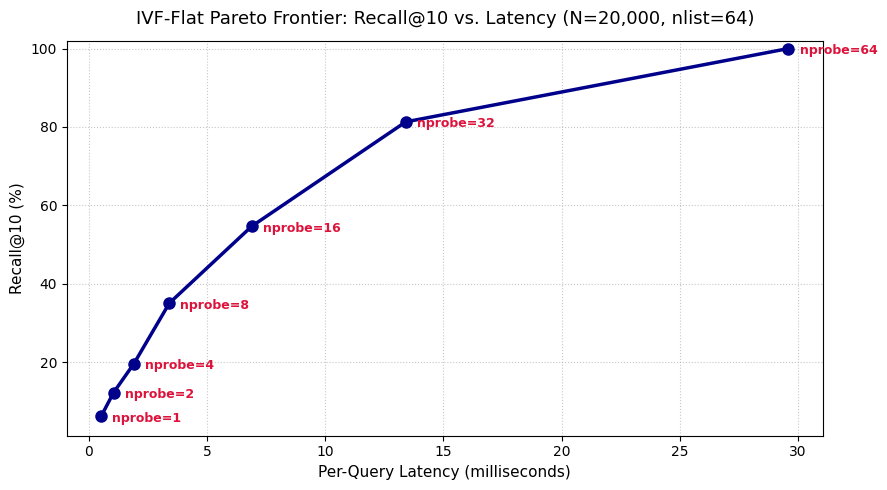

In [8]:
plt.figure(figsize=(9, 5))
plt.plot(latencies_ms, [r * 100 for r in recalls], 'o-', color='darkblue', linewidth=2.5, markersize=8)

for i, txt in enumerate(nprobe_sweep):
    plt.annotate(f"nprobe={txt}", (latencies_ms[i], recalls[i] * 100), 
                 textcoords="offset points", xytext=(8, -4), fontsize=9, fontweight='bold', color='crimson')

plt.title(f"IVF-Flat Pareto Frontier: Recall@10 vs. Latency (N={N_BENCH:,d}, nlist={NLIST_VAL})", fontsize=13, pad=12)
plt.xlabel("Per-Query Latency (milliseconds)", fontsize=11)
plt.ylabel("Recall@10 (%)", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.7)
plt.ylim(min(recalls)*100 - 5, 102)
plt.tight_layout()
plt.show()


---
## 7. Industry Reference Comparison (Faiss `IndexIVFFlat`)

In production environments, **Faiss** implements `IndexIVFFlat` with heavily optimized AVX-512 SIMD vectorization and parallel coarse quantization.

### How Faiss configures an IVF index:
1. **Quantizer**: An underlying Flat index (`IndexFlatL2` or `IndexFlatIP`) used solely to search centroids.
2. **IndexIVFFlat**: Wraps the quantizer with `nlist` inverted lists.
3. **Parameter `nprobe`**: Set dynamically at query time via `index.nprobe = 8`.

Let's test Faiss side-by-side with our scratch index!


In [ ]:
try:
    import faiss
    
    # 1. Create coarse quantizer (IndexFlatL2)
    quantizer = faiss.IndexFlatL2(D_BENCH)
    
    # 2. Wrap in IndexIVFFlat
    faiss_ivf = faiss.IndexIVFFlat(quantizer, D_BENCH, NLIST_VAL, faiss.METRIC_L2)
    
    # 3. Train centroids
    t0 = time.perf_counter()
    faiss_ivf.train(eval_corpus)
    train_time = (time.perf_counter() - t0) * 1000.0
    
    # 4. Ingest corpus
    faiss_ivf.add(eval_corpus)
    
    # 5. Search with nprobe = 8
    faiss_ivf.nprobe = 8
    t0 = time.perf_counter()
    faiss_dists, faiss_ids = faiss_ivf.search(eval_queries, K_TARGET)
    faiss_search_time = (time.perf_counter() - t0) * 1000.0
    
    # 6. Evaluate Faiss Recall
    faiss_recalls = [
        len(set(ground_truth_topk[i]).intersection(set(faiss_ids[i]))) / float(K_TARGET)
        for i in range(N_QUERIES)
    ]
    avg_faiss_recall = np.mean(faiss_recalls)
    
    print("Faiss IndexIVFFlat Benchmark:")
    print(f"  Training Time:      {train_time:.2f} ms")
    print(f"  Total Search Time:  {faiss_search_time:.2f} ms for {N_QUERIES} queries")
    print(f"  Average Latency:    {faiss_search_time / N_QUERIES:.3f} ms / query")
    print(f"  Throughput:         {N_QUERIES / (faiss_search_time / 1000.0):.1f} QPS")
    print(f"  Recall@10:          {avg_faiss_recall * 100:.2f}%")
    print("\n Faiss verified successfully against scratch concepts!")

except ImportError:
    print("Faiss not installed in this environment; skipping Faiss comparison.")
    print("To install: pip install faiss-cpu")


---
## 8. Pros, Cons & Production Failure Modes

### IVF-Flat Tradeoff Matrix

| Feature | Advantage (Pros) | Limitation (Cons) |
| :--- | :--- | :--- |
| **Query Speed** | Fast sub-linear search: scans only $\frac{\text{nprobe}}{\text{nlist}}$ of the dataset ($5\times$ to $50\times$ faster than Flat). | Still requires scanning all vectors within the selected cells (does not reduce vector dimensionality or RAM). |
| **Tunability** | Dynamic runtime control: adjust `nprobe` on the fly to trade latency for recall without rebuilding the index. | Hyperparameter sensitivity: picking bad `nlist` or `nprobe` degrades performance. |
| **Index Footprint** | Extremely low memory overhead: only stores an array of centroid coordinates plus tiny integer posting list pointers. | Stores raw float32 vectors in RAM (RAM crisis persists for millions of vectors). |
| **Build Time** | Moderate: K-Means training on a sample of $100,000$ vectors takes only seconds to minutes. | Requires retraining if the semantic distribution of the corpus drifts significantly. |

---

### Critical Production Failure Modes & How to Avoid Them:

#### 1. The Centroid Skew Problem (Imbalanced Clusters)
- **Problem**: K-Means clustering in high dimensions can produce severe cluster imbalance. One "super-cluster" may contain $25\%$ of all vectors in the database, while other clusters are nearly empty.
- **Symptom**: If a query happens to land in the super-cluster, query latency spikes by $10\times$ because the engine must scan thousands of vectors in that single list!
- **Mitigation**: Monitor cluster size variance. Use spherical K-Means or balanced K-Means algorithms.

#### 2. The Semantic Drift / Stale Centroids Problem
- **Problem**: In RAG, documents are added continuously. If the coarse centroids were trained on 2024 data (e.g., general finance), but new documents in 2026 cover a completely new domain (e.g., Quantum Computing), new embeddings will be crammed into whichever old centroid is marginally closest.
- **Symptom**: Recall steadily degrades over time as new vectors clump unnaturally into distant Voronoi cells.
- **Mitigation**: Re-train the IVF coarse quantizer periodically (e.g., weekly or monthly) when corpus size grows by $>25\%$.

#### 3. Hyperparameter Rule of Thumb: How to pick `nlist`?
- **Faiss Recommendation**:
  $$\text{nlist} \approx 4 \cdot \sqrt{N}$$
  For example, for $N = 1,000,000$ vectors:
  $$\text{nlist} \approx 4 \times 1,000 = 4,000 \text{ clusters}$$
- **Query Setting**: Set `nprobe` between $1\%$ and $5\%$ of `nlist` (e.g., `nprobe = 16` to `64` for 4,000 clusters) to achieve $>95\%$ Recall@10.


---
## 9. Summary & What's Next

### Key Takeaways from Notebook 03:
1. **The ANN Paradigm**: Breaks the $O(N)$ linear scan by trading a minor amount of recall ($2\%$–$5\%$) for orders of magnitude faster queries.
2. **Voronoi Space Partitioning**: Partitions the embedding space into `nlist` geometric cells centered at K-Means centroids.
3. **Inverted Lists**: Ingestion routes vectors to their nearest centroid's posting list.
4. **Query Routing via `nprobe`**: Queries only scan the vectors within the `nprobe` closest Voronoi cells, pruning $90\%$ to $99\%$ of candidates!
5. **The Boundary Problem**: Vectors near cell borders can be missed if `nprobe` is too small. Increasing `nprobe` traces the Pareto Frontier between speed and accuracy.

---

### But One Fatal Bottleneck Remains...
Notice that while IVF solved the **compute bottleneck** (scanning fewer vectors), **it did NOT solve the RAM bottleneck**!
Every vector in an IVF-Flat index is still stored as an uncompressed 768-dimensional `float32` array ($3,072$ bytes per vector).
Storing $10,000,000$ vectors still requires **$30.72$ GB of high-speed RAM**!

In the next notebook, we solve the RAM crisis once and for all:

👉 **Notebook 04: Product Quantization (PQ) & IVF-PQ (Vector Compression)**
- Compressing 768-dim float32 vectors down to tiny 64-byte codes ($98\%$ memory reduction!).
- Splitting vectors into orthogonal sub-vectors and learning sub-space codebooks.
- Asymmetric Distance Computation (ADC) using precomputed Lookup Tables (LUT).
- Combining **IVF + PQ (IVF-PQ)**: The industrial architecture that powers billion-scale vector search!
